# Assignment 1 · Part 1 — Kinematic chains
## 50 points

In a kinematic chain, rotating one joint moves everything attached to it; body models of virtual humans are such chains. This part develops the mathematics on a planar arm:
rotation about a point, homogeneous transforms, and their composition along the chain (Lecture 02.2, slides 7–11, 42–43 and 46–50).

*Optional: the interactive companion `assignment_1_lab.html` (open it in a browser; tabs "Rotation", "Two joints", "Workspace") visualises the concepts of this part. Nothing in this notebook depends on it.*

### Team members

**Every submission must state the full names and the matriculation numbers of all team members (at most three) here, at the start of `part_1.ipynb`.**
Double-click this cell and replace the placeholders.

| Name | Matriculation number |
|---|---|
| Melanie Holfort Sansores | 7438480 |
| Giorgi Gogelashvili | 7312678 |
| … | … |

### Instructions

Complete the code between `START OF YOUR SOLUTION` and `END OF YOUR SOLUTION` (replace every `None`) and answer the written questions in the cells headed **Answer**.
A check cell follows each coding block; it compares your functions with reference values and is meant as a self-test — grading is based on your code and your written answers.
Inside formulas angles are in radians (`np.deg2rad` converts degrees); rotations are counter-clockwise. Submit the notebook together with a PDF export, one submission per team.

### Notation used in this part

| Symbol | Meaning |
|---|---|
| $\mathbf{x}=(x,y)^\top\in\mathbb{R}^2$ | a point in the spatial frame S; $\bar{\mathbf{x}}=(x,y,1)^\top$ its homogeneous coordinates |
| $\mathbf{R}(\theta)=\begin{bmatrix}\cos\theta&-\sin\theta\\ \sin\theta&\cos\theta\end{bmatrix}$ | counter-clockwise rotation by $\theta$ (about the origin) |
| $\mathbf{q}_i$ | **rest** position of joint $i$ (all angles zero); the joint is a revolute (hinge) joint |
| $\mathbf{a}_i=\mathbf{q}_{i+1}-\mathbf{q}_i$ | link vector at rest; the last link ends in the arm end $\mathbf{e}$ |
| $\mathbf{c}^{+},\mathbf{c}^{-}$ | offsets of the two claw tips from the arm end $\mathbf{e}$ (rigidly attached): the tips are at $\mathbf{e}+\mathbf{c}^{+}$ and $\mathbf{e}+\mathbf{c}^{-}$ |
| $\theta_i$ | angle of joint $i$ **relative** to its parent (everything beyond joint $i$ turns by $\theta_i$ about $\mathbf{q}_i$) |
| $\mathbf{T}(\mathbf{q},\theta)=\begin{bmatrix}\mathbf{R}(\theta)&\mathbf{q}-\mathbf{R}(\theta)\mathbf{q}\\ \mathbf{0}^\top&1\end{bmatrix}$ | rotation about the point $\mathbf{q}$, as a $3\times3$ homogeneous matrix ($=\exp(\hat{\xi}\theta)$ for a revolute joint at $\mathbf{q}$) |
| $\bar{\mathbf{p}}(\theta_1,\dots,\theta_k)=\mathbf{T}_1(\theta_1)\cdots\mathbf{T}_k(\theta_k)\,\bar{\mathbf{p}}(\mathbf{0})$ | position of a point $\mathbf{p}$ on the link after joint $k$, with $\mathbf{T}_i=\mathbf{T}(\mathbf{q}_i,\cdot)$ built from the **rest** positions |

In [ ]:
#@title Setup — run this cell first
import os, sys, zipfile

# The helper package `vh_a1` (plots, given functions, self-checks) ships as vh_a1.zip next to this notebook.
if not os.path.isdir("vh_a1"):
    if not os.path.exists("vh_a1.zip") and "google.colab" in sys.modules:
        from google.colab import files
        print("Select the file vh_a1.zip (part of the assignment material):")
        uploaded = files.upload()
        if uploaded:
            os.replace(next(iter(uploaded)), "vh_a1.zip")
    if not os.path.exists("vh_a1.zip"):
        raise RuntimeError("Package not found: put the folder vh_a1/ or the file vh_a1.zip next to this notebook and run this cell again.")
    zipfile.ZipFile("vh_a1.zip").extractall(".")

%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from vh_a1 import params
from vh_a1.common import Checker, progress, ready
np.set_printoptions(precision=4, suppress=True)

Select the file vh_a1.zip (part of the assignment material):


Saving vh_a1.zip to vh_a1.zip


In [ ]:
from vh_a1.part1 import new_axes, draw_chain, scatter_workspace, coverage

def hom(p):   return np.append(p, 1.0)       # (x, y)    -> (x, y, 1)
def dehom(p): return p[:2] / p[2]           # (x, y, w) -> (x/w, y/w)

## The robot

We start with one revolute joint at $\mathbf{q}=\mathbf{q}_1$, a rigid arm $\mathbf{a}$ and, at its end $\mathbf{e}=\mathbf{q}+\mathbf{a}$, a claw
(two rigid segments ending in the tips $\mathbf{e}+\mathbf{c}^{+}$ and $\mathbf{e}+\mathbf{c}^{-}$). At rest all angles are zero.

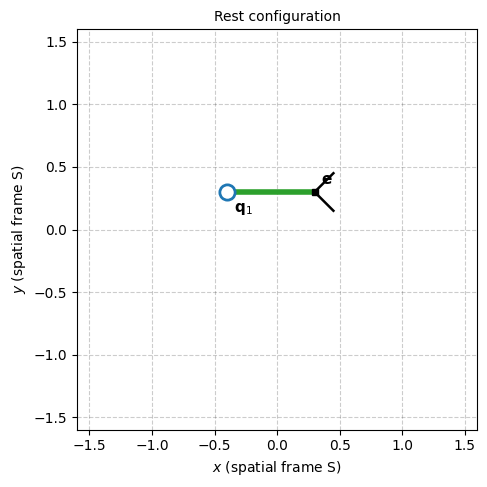

In [ ]:
q    = params.Q1                                   # rest position of the joint, q
a    = params.LINKS_2[0]                           # rest link vector, a
e    = q + a                                       # rest position of the arm end, e
c_up = e + params.CLAW_UP                          # rest position of the claw tips
c_lo = e + params.CLAW_LO

ax = new_axes("Rest configuration", window=params.ZOOM)
draw_chain(ax, [q], e, c_up, c_lo)
plt.show()

## Task 1.1 · Single joint: apply a rotation (5 points)

A joint turns everything attached to it **about the joint**. For a point $\mathbf{x}$ on the arm,

$$\mathbf{x}' \;=\; \mathbf{q} + \mathbf{R}(\theta)\,(\mathbf{x}-\mathbf{q}). \tag{1}$$

Note that (1) is *not* $\mathbf{R}(\theta)\mathbf{x}$: that would rotate about the origin of S, not about the joint.

**Task.** Implement $\mathbf{R}(\theta)$ and equation (1), then rotate the arm end $\mathbf{e}$ and both claw tips by $\theta=50^\circ$ (counter-clockwise).

In [ ]:
theta = np.deg2rad(params.THETA_SEC1_DEG)          # 50 degrees, in radians

#### START OF YOUR SOLUTION ####
def rot2(theta):
    """R(theta): 2x2 counter-clockwise rotation matrix."""
    return np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta), np.cos(theta)]
    ])

def rotate_about(x, q, theta):
    """Equation (1): rotate the point x about the point q by theta."""
    return q + rot2(theta) @ (x - q)

e_new  = rotate_about(e, q, theta)
cu_new = rotate_about(c_up, q, theta)
cl_new = rotate_about(c_lo, q, theta)
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.1")
chk.close("R(90°) = [[0,-1],[1,0]]", lambda: rot2(np.pi / 2), [[0, -1], [1, 0]], atol=1e-9,
          hint="counter-clockwise: R(θ) = [[cos θ, -sin θ], [sin θ, cos θ]]")
chk.close("R(30°)", lambda: rot2(np.deg2rad(30)), [[0.866025, -0.5], [0.5, 0.866025]], hint="radians, not degrees")
chk.close("the joint itself does not move: rotate_about(q, q, θ) = q", lambda: rotate_about(q, q, 1.0), q)
chk.close("rotate_about(e, q, 50°)", lambda: rotate_about(e, q, theta), [0.049951, 0.836231])
chk.close("e'  (your variable e_new)", lambda: e_new, [0.049951, 0.836231])
chk.close("claw tip e + c⁺ after the rotation (your variable cu_new)", lambda: cu_new, [0.031463, 1.047556])
chk.close("claw tip e + c⁻ after the rotation (your variable cl_new)", lambda: cl_new, [0.261276, 0.85472])
chk.test("the claw turns rigidly with the arm: the tip e + c⁺ moves to e' + R(θ) c⁺",
         lambda: None if not ready(cu_new, e_new, rot2(theta)) else np.allclose(cu_new, e_new + rot2(theta) @ params.CLAW_UP))

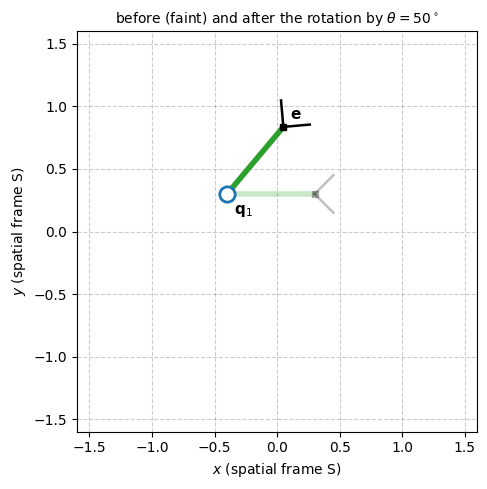

In [ ]:
if ready(e_new, cu_new, cl_new):
    ax = new_axes(r"before (faint) and after the rotation by $\theta=50^\circ$", window=params.ZOOM)
    draw_chain(ax, [q], e, c_up, c_lo, alpha=0.25, label=False)
    draw_chain(ax, [q], e_new, cu_new, cl_new)
    plt.show()
else:
    print("The plot appears as soon as the cells above are implemented.")

**Answer** (double-click to edit)

1. Which representation of the rotation did you use, and what exactly does it act on? <br />
  *A 2x2 rotation matrix that acts on the point's position relative to the joint*
2. Why does the joint position $\mathbf{q}$ not change? <br />
  *The relative position is zero and rotating a zero vector leaves it as zero*
3. How are the arm end $\mathbf{e}$ and the claw tips updated, and why? (Show that the tip $\mathbf{e}+\mathbf{c}^{\pm}$ moves to $\mathbf{e}'+\mathbf{R}(\theta)\mathbf{c}^{\pm}$.) <br />
  *Each point is rotated around q and since the claw is rigidly attached the offset vectors rotate as well*
4. Why do we subtract $\mathbf{q}$ in (1) instead of just computing $\mathbf{R}(\theta)\mathbf{x}$? <br />
  *The matrix rotates around the origin, subtracting q changes the reference point to the joint, adding it afterward changes it back*

## Task 1.2 · Single joint: the space of configurations (5 points)

Which points can the arm end reach? Sample the joint angle at $N=50$ equally spaced values $\alpha_j=2\pi j/N$, $j=0,\dots,N-1$
(note: **without** repeating $2\pi$) and collect the resulting arm end positions $\mathbf{e}(\alpha_j)$ in `final_pos` (an array of shape $(50,2)$).

In [ ]:
#### START OF YOUR SOLUTION ####
n = 50
angles = 2 * np.pi * np.arange(n) / n

final_pos = np.array([
    q + rot2(alpha) @ a
    for alpha in angles
])
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.2")
chk.test("final_pos has shape (50, 2)", lambda: None if final_pos is None else (np.shape(final_pos) == (50, 2), f"shape {np.shape(final_pos)}"))
chk.test("every point is at distance |a| from the joint",
         lambda: None if final_pos is None else bool(np.allclose(np.linalg.norm(np.asarray(final_pos) - q, axis=1), np.linalg.norm(a))))
chk.test("the 50 angles are equally spaced and do not repeat 2π (the points' centroid is q)",
         lambda: None if final_pos is None else bool(np.allclose(np.mean(final_pos, axis=0), q, atol=1e-9)),
         hint="use np.arange or np.linspace(..., endpoint=False)")
chk.close("the first row is e(α₀) = q + a: the angles start at 0", lambda: None if final_pos is None else np.asarray(final_pos)[0], [0.3, 0.3])
chk.close("the second row is e(2π/50): the angles increase (counter-clockwise)", lambda: None if final_pos is None else np.asarray(final_pos)[1], [0.29448, 0.387733])

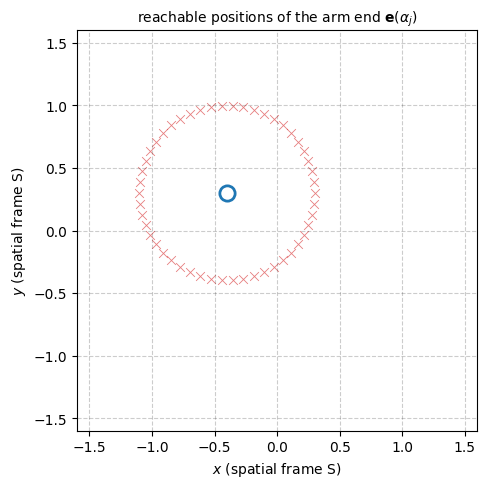

In [ ]:
if ready(final_pos):
    ax = new_axes(r"reachable positions of the arm end $\mathbf{e}(\alpha_j)$", window=params.ZOOM)
    scatter_workspace(ax, final_pos, s=40)
    ax.plot(*q, "o", mfc="white", mec="tab:blue", mew=2, ms=11)
    plt.show()

**Answer**

1. Give $\mathbf{e}(\alpha)=(e_x(\alpha),\,e_y(\alpha))^\top$ as a function of the angle $\alpha$, in terms of $\mathbf{q}=(q_x,q_y)^\top$ and $\mathbf{a}=(a_x,a_y)^\top$:<br />
  $e_x(\alpha)= q_x + a_x \cos \alpha - a_y \sin \alpha$ <br />
  $e_y(\alpha)= q_y + a_x \sin \alpha + a_y \cos \alpha$ <br />
2. What set of points does $\mathbf{e}(\alpha)$ trace when $\alpha$ runs over $[0,2\pi)$? <br />
  *It traces a circle around the joint. Every point in the circle is reachable and all points inside or outside cannot be reached beacuse the arm has a set length*

## Task 1.3 · Two joints: apply rotations (12 points)

Add a second joint at $\mathbf{q}_2=\mathbf{q}_1+\mathbf{a}_1$ and a second link $\mathbf{a}_2$; the claw now sits at the end of link 2.
Joint angles are **relative**: $\theta_2$ is measured against link 1.

To handle several rotations with *different centres* we use the homogeneous form of rotation about a point,
$$\mathbf{T}(\mathbf{q},\theta)=\begin{bmatrix}\mathbf{R}(\theta)&\mathbf{q}-\mathbf{R}(\theta)\mathbf{q}\\ \mathbf{0}^\top&1\end{bmatrix},\qquad
\bar{\mathbf{x}}'=\mathbf{T}(\mathbf{q},\theta)\,\bar{\mathbf{x}}\;\;\Longleftrightarrow\;\;\mathbf{x}'=\mathbf{q}+\mathbf{R}(\theta)(\mathbf{x}-\mathbf{q}). \tag{2}$$

For a point on link 2 the product of exponentials of the lecture reads (the $\mathbf{q}_i$ are the **rest** positions)
$$\bar{\mathbf{p}}(\theta_1,\theta_2)=\mathbf{T}_1(\theta_1)\,\mathbf{T}_2(\theta_2)\,\bar{\mathbf{p}}(\mathbf{0}),\qquad \mathbf{T}_i(\theta_i)=\mathbf{T}(\mathbf{q}_i,\theta_i). \tag{3}$$
Read it from the right: first joint 2 turns link 2 (about its rest hinge $\mathbf{q}_2$), then joint 1 turns link 1 **and everything beyond it**.

**Task.** (i) Implement $\mathbf{T}(\mathbf{q},\theta)$. (ii) Move the arm for
 (a) $(\theta_1,\theta_2)=(70^\circ,\,0^\circ)$: joint 1 turns, joint 2 does not,
 (b) $(\theta_1,\theta_2)=(70^\circ,\,40^\circ)$,
and store the new positions of joint 2 ($\mathbf{q}_2$), the arm end ($\mathbf{e}$) and the two claw tips. Think about **which** transforms act on **which** point.

In [ ]:
Q2, e2 = params.rest_chain(params.LINKS_2)          # Q2[0] = q_1, Q2[1] = q_2 ; e2 = arm end at rest
cu2, cl2 = e2 + params.CLAW_UP, e2 + params.CLAW_LO
theta_a = np.deg2rad(params.THETA_SEC3A_DEG)        # (70°,  0°)
theta_b = np.deg2rad(params.THETA_SEC3B_DEG)        # (70°, 40°)

#### START OF YOUR SOLUTION ####
def T(q, theta):
    """Equation (2): 3x3 homogeneous matrix of the rotation about the point q by theta."""
    R = rot2(theta)
    return np.block([
        [R, (q - R @ q).reshape(2, 1)],
        [np.zeros((1, 2)), np.ones((1, 1))]
    ])

# Transformation matrices
T1_a = T(Q2[0], theta_a[0])
T2_a = T(Q2[1], theta_a[1])

T1_b = T(Q2[0], theta_b[0])
T2_b = T(Q2[1], theta_b[1])

# (a) theta = (70°, 0°)
q2_a = dehom(T1_a @ hom(Q2[1]))
e_a = dehom(T1_a @ T2_a @ hom(e2))
cu_a = dehom(T1_a @ T2_a @ hom(cu2))
cl_a = dehom(T1_a @ T2_a @ hom(cl2))

# (b) theta = (70°, 40°)
q2_b = dehom(T1_b @ hom(Q2[1]))
e_b = dehom(T1_b @ T2_b @ hom(e2))
cu_b = dehom(T1_b @ T2_b @ hom(cu2))
cl_b = dehom(T1_b @ T2_b @ hom(cl2))
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.3")
chk.close("T(q, 30°) for q = (1, 2)", lambda: T(np.array([1.0, 2.0]), np.deg2rad(30)), [[0.866025, -0.5, 1.133975], [0.5, 0.866025, -0.232051], [0.0, 0.0, 1.0]],
          hint="the translation column is q − R(θ) q")
chk.close("T leaves its own centre fixed", lambda: None if T(np.array([1.0, 2.0]), 0.7) is None else dehom(T(np.array([1.0, 2.0]), 0.7) @ hom(np.array([1.0, 2.0]))), [1.0, 2.0])
chk.close("(a) q_2", lambda: q2_a, [-0.160586, 0.957785])
chk.close("(a) e",   lambda: e_a,  [-0.075081, 1.192708])
chk.close("(a) claw tip e + c⁺",  lambda: cu_a, [-0.164732, 1.384965])
chk.close("(a) claw tip e + c⁻",  lambda: cl_a, [0.117176, 1.282359])
chk.close("(b) q_2 (only joint 1 moves it)", lambda: q2_b, [-0.160586, 0.957785])
chk.close("(b) e",   lambda: e_b,  [-0.246091, 1.192708], hint="e feels both joints: T_1 T_2 applied to e")
chk.close("(b) claw tip e + c⁺",  lambda: cu_b, [-0.438348, 1.282359])
chk.close("(b) claw tip e + c⁻",  lambda: cl_b, [-0.15644, 1.384965])

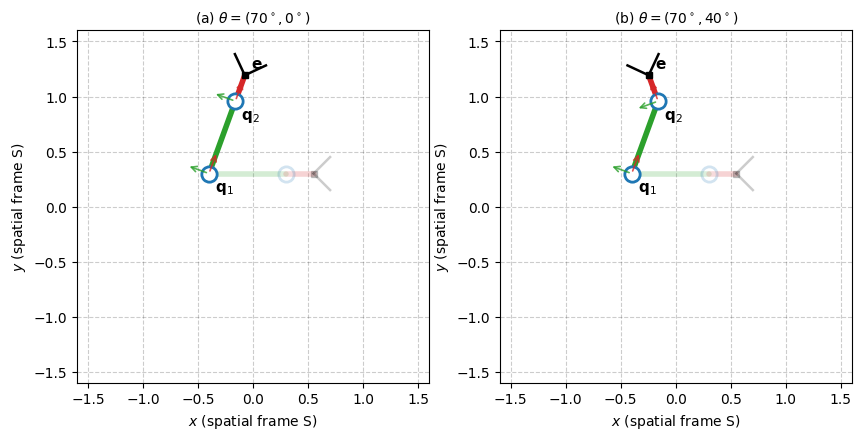

In [ ]:
if ready(q2_a, e_a, cu_a, cl_a, q2_b, e_b, cu_b, cl_b):
    fig, axs = plt.subplots(1, 2, figsize=(10, 5))
    for ax, (title, th, q2n, en, cun, cln) in zip(axs, [(r"(a) $\theta=(70^\circ,0^\circ)$", theta_a, q2_a, e_a, cu_a, cl_a),
                                                          (r"(b) $\theta=(70^\circ,40^\circ)$", theta_b, q2_b, e_b, cu_b, cl_b)]):
        new_axes(title, window=params.ZOOM, ax=ax)
        draw_chain(ax, Q2, e2, cu2, cl2, alpha=0.2, label=False)
        draw_chain(ax, [Q2[0], q2n], en, cun, cln, thetas=th, frames=True)
    plt.show()
else:
    print("The plot appears as soon as the cells above are implemented.")

**Compare the two possible orders** of the product. For $(\theta_1,\theta_2)=(70^\circ,40^\circ)$ compute both
$\mathbf{T}_{12}=\mathbf{T}_1(\theta_1)\mathbf{T}_2(\theta_2)$ and $\mathbf{T}_{21}=\mathbf{T}_2(\theta_2)\mathbf{T}_1(\theta_1)$.

In [ ]:
#### START OF YOUR SOLUTION ####
T12 = T(Q2[0], theta_b[0]) @ T(Q2[1], theta_b[1])
T21 = T(Q2[1], theta_b[1]) @ T(Q2[0], theta_b[0])
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.3 (order of the chain)")
chk.close("T_12 = T_1(θ_1) T_2(θ_2)", lambda: T12, [[-0.34202, -0.939693, 0.223928], [0.939693, -0.34202, 0.778483], [0.0, 0.0, 1.0]])
chk.test("T_12 and T_21 are different matrices", lambda: None if not ready(T12, T21) else not np.allclose(T12, T21))
chk.test("...but their rotation blocks are equal", lambda: None if not ready(T12, T21) else bool(np.allclose(T12[:2, :2], T21[:2, :2])))
chk.close("end point if the two angles are swapped (θ_1, θ_2) = (40°, 70°)",
          lambda: dehom(T(Q2[0], np.deg2rad(40)) @ T(Q2[1], np.deg2rad(70)) @ hom(e2)), [0.050726, 0.984874])

**Answer**

1. Which of the transforms $\mathbf{T}_1,\mathbf{T}_2$ act on (i) $\mathbf{q}_1$, (ii) $\mathbf{q}_2$, (iii) $\mathbf{e}$ and the claw tips? Why does $\mathbf{T}_2$ not move $\mathbf{q}_2$ but $\mathbf{T}_1$ does? <br />
  *Each transform describes the rotation of a joint around its own pivot* <br />
  *$T_1$ rotates around $q_1$ so $q_1$ remains fixed while $q_2$, $e$ and the claw tips are attached to the first link so they move with the rotation* <br />
  *$T_2$ rotates around $q_2$ so it remains fixed while $e$ and the claw tips move* <br />
  *The reason $T_2$ does not move $q_2$ is that it is the pivot of the rotation. $T_1$ moves it because it rotates around a different pivot*

2. $\mathbf{T}_{12}\ne\mathbf{T}_{21}$, yet planar rotations $\mathbf{R}(\theta_1)\mathbf{R}(\theta_2)=\mathbf{R}(\theta_2)\mathbf{R}(\theta_1)$ commute. Explain. Which order is the correct chain, and why? <br />
  *The matrices are different because the transformations rotate around different centers so the translation depends on the order in which the transformations are applied. Typically 2D rotations commute when they rotate around the same origin but the complete transformation also includes translation so thed no longer commute. The correct order is T12 because the second joint is attached to the first link and the first joints rotation must be applied before*

3. We swap the two angles, $(\theta_1,\theta_2)=(40^\circ,70^\circ)$. Is the arm end the same? Give a reason using $\mathbf{e}=\mathbf{q}_1+\mathbf{R}(\theta_1)\mathbf{a}_1+\mathbf{R}(\theta_1+\theta_2)\mathbf{a}_2$. <br />
  *In the equation we can see that the first link depends only on theta 1 while the second depends on the sum of the angles. When swapping the angles the sum remains unchanged so the second links rotation stays the same. The second linke however changes direction so its contribution to the endpoint changes resulting in a different position.*

## Task 1.4 · Two joints: the space of configurations (16 points)

Now let both joints sweep a full turn. Use the angle grid $\vartheta_j=2\pi j/N$, $j=0,\dots,N-1$, with $N=100$ for **each** joint
(`np.meshgrid` helps) — that is $N^2=10\,000$ configurations — and collect the arm end for every pair $(\theta_1,\theta_2)$ of grid values.

Write the computation as a **function** of the link vectors, so that you can re-use it for other arm lengths below.

In [ ]:
#### START OF YOUR SOLUTION ####
def workspace(links, n=params.N_SEC4):
    """Arm end for all n x n pairs (theta_1, theta_2), angles 2*pi*j/n, j = 0..n-1. Returns an array of shape (n*n, 2)."""
    Qw, ew = params.rest_chain(links)               # rest joints and rest arm end of this arm

    angles = 2 * np.pi * np.arange(n) / n
    theta1, theta2 = np.meshgrid(angles, angles)

    a1, a2 = links[0], links[1]
    q1 = Qw[0]

    theta1 = theta1.ravel()
    theta2 = theta2.ravel()

    positions = []
    for t1, t2 in zip(theta1, theta2):
        p = (q1
             + rot2(t1) @ a1
             + rot2(t1 + t2) @ a2)
        positions.append(p)

    return np.array(positions)
#### END OF YOUR SOLUTION ####

In [ ]:
ws_pos = workspace(params.LINKS_2)
chk = Checker("Part 1 · Task 1.4")
def _stats():
    if ws_pos is None: return None
    p = np.asarray(ws_pos, float).reshape(-1, 2)
    r = np.hypot(p[:, 0] - params.Q1[0], p[:, 1] - params.Q1[1])
    return [len(p), p[:, 0].sum(), p[:, 1].sum(), (p[:, 0] ** 2).sum(), (p[:, 1] ** 2).sum(), (p[:, 0] * p[:, 1]).sum(), r.min(), r.max()]
chk.close("10 000 arm-end positions with the right distribution (order-independent fingerprint)", _stats, [10000.0, -4000.0, 3000.0, 4362.5, 3662.5, -1200.0, 0.45, 0.95], atol=1e-4,
          hint="every pair (θ_1, θ_2) of the grid exactly once; rotate with T_1 T_2 — don't accumulate rotations from one iteration to the next")

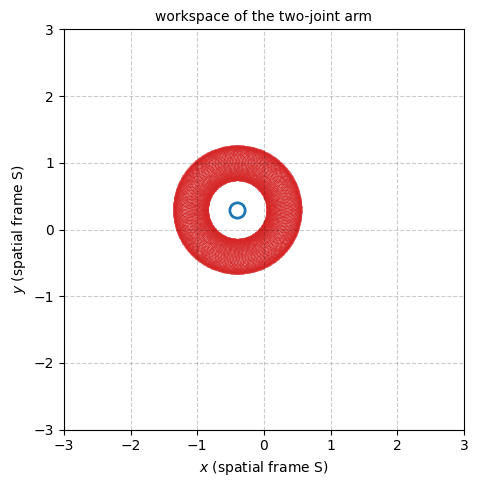

In [ ]:
if ready(ws_pos):
    ax = new_axes("workspace of the two-joint arm")
    scatter_workspace(ax, ws_pos, s=2)
    ax.plot(*params.Q1, "o", mfc="white", mec="tab:blue", mew=2, ms=11)
    plt.show()

**Experiments.** (1) Make the second link longer than the first, $\mathbf{a}_2=(\ell_2,0)^\top$ with $\ell_2>\ell_1=0.7$, and rerun. (2) Find link lengths $\ell_1,\ell_2$ such that the arm can reach (essentially) the **whole** window $[-3,3]^2$.
The meter below runs **your** `workspace` with $N=200$ and reports the fraction of the window (in cells of side $0.2$) that contains at least one of your points.

In [ ]:
#### START OF YOUR SOLUTION ####
l2_long  = 0.9
l1_cover = l2_cover = 2.3
#### END OF YOUR SOLUTION ####

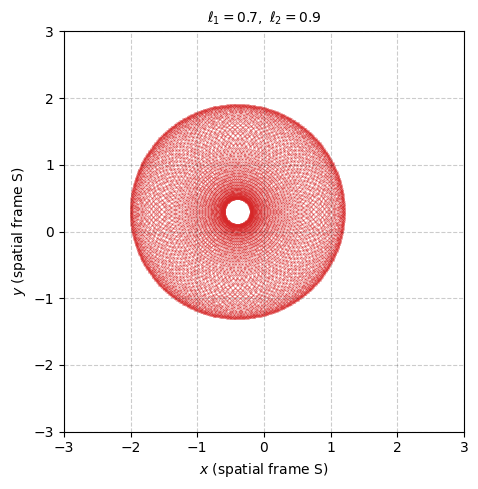

ℓ1 = 2.3, ℓ2 = 2.3:  your arm hits 100.0 % of the window [-3,3]² (cells of 0.2)


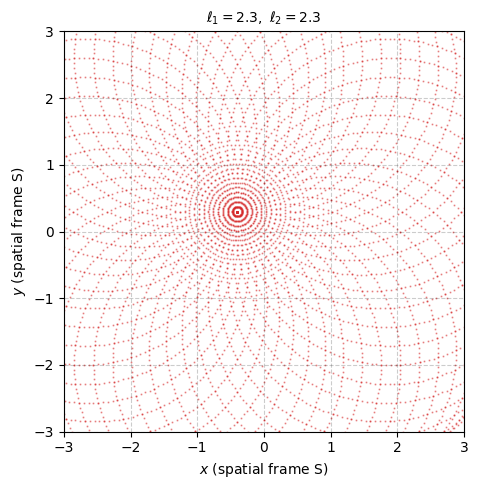

In [ ]:
def reach(l1, l2, n=200):
    """Points reached by an arm with link lengths l1, l2 (uses YOUR workspace function)."""
    return workspace(np.array([[l1, 0.0], [l2, 0.0]]), n=n)

if ready(l2_long, reach(0.7, 0.25, n=4)):
    ax = new_axes(rf"$\ell_1=0.7,\ \ell_2={l2_long}$")
    scatter_workspace(ax, reach(0.7, l2_long, n=100), s=2)
    plt.show()
if ready(l1_cover, l2_cover, reach(0.7, 0.25, n=4)):
    pts = reach(l1_cover, l2_cover)
    print(f"ℓ1 = {l1_cover}, ℓ2 = {l2_cover}:  your arm hits {100 * coverage(pts):.1f} % of the window [-3,3]² (cells of 0.2)")
    ax = new_axes(rf"$\ell_1={l1_cover},\ \ell_2={l2_cover}$")
    scatter_workspace(ax, pts[::4], s=1)
    plt.show()

In [ ]:
chk = Checker("Part 1 · Task 1.4 (experiments)")
chk.test("the second link is longer than the first (ℓ₂ > 0.7)", lambda: None if l2_long is None else l2_long > 0.7)
chk.test("your lengths cover ≥ 99.5 % of the window", lambda: None if l1_cover is None or l2_cover is None or reach(l1_cover, l2_cover, n=4) is None else
         (coverage(reach(l1_cover, l2_cover)) >= 0.995, f"coverage = {100 * coverage(reach(l1_cover, l2_cover)):.1f} %"),
         hint="what does the hole in the middle of the workspace depend on, and how far is the farthest corner of the window from q_1?")

**Answer**

1. What does the set of reachable points look like? Give it in closed form in terms of $\ell_1=\|\mathbf{a}_1\|$, $\ell_2=\|\mathbf{a}_2\|$ and $\mathbf{q}_1$ (which radii?). Which points are **not** reachable? <br />
  *It looks like a ring, the outer edge has the radius $\ell_1 + \ell_2$ and the inner edge has the radius $\ell_1 - \ell_2$. All points outside of the ring, meaning all points not in between the edges or on the edges, are not reachable.*
2. How does it change when the second link is longer (your `l2_long`)? What happens at $\ell_2=\ell_1$ and beyond? <br />
  *When both links have the same length the inner radius is zero.  When the second link becomes larger than the first one, the inner radius begins growing again since the minimum reachable distance is the absolute difference between the two lengths.*
3. Which lengths did you choose to cover the window, and why (derive them)? <br />
  *To cover the complete area, the arm must be able to reach the corners which are the farthest points. The distance from the first joint at the origin is $r_=\sqrt{3^2+3^2}=\sqrt{18}\approx4.24$. The sum of the link lengths has to be at least 4.24. We chose equal link lengths of 2.3 that gives a mamimum reach of 4.6 and an inner radius of 0*

## Task 1.5 · Three joints (12 points)

Finally a three-joint arm (all links $0.35$ long). Generalise what you did: write **one** function that moves any rest point $\mathbf{p}$ lying beyond the first $k$ joints,
$$\bar{\mathbf{p}}'=\mathbf{T}_1(\theta_1)\cdots\mathbf{T}_k(\theta_k)\,\bar{\mathbf{p}},$$
and use it for the angles $(\theta_1,\theta_2,\theta_3)=(40^\circ,-80^\circ,40^\circ)$.

In [ ]:
Q3, e3 = params.rest_chain(params.LINKS_3)         # rest joints (3,2) and rest arm end
cu3, cl3 = e3 + params.CLAW_UP, e3 + params.CLAW_LO
theta5 = np.deg2rad(params.THETA_SEC5_DEG)

#### START OF YOUR SOLUTION ####
def forward_kinematics(Q, thetas, p, k):
    """Position of the rest point p after the first k joints (rest positions Q, angles thetas; only thetas[:k] are used) have moved."""
    point = hom(p)

    for i in reversed(range(k)):
      point = T(Q[i], thetas[i]) @ point

    return dehom(point)


joints5 = np.array([
    forward_kinematics(Q3, theta5, Q3[0], 0),
    forward_kinematics(Q3, theta5, Q3[1], 1),
    forward_kinematics(Q3, theta5, Q3[2], 2)
])

e5 = forward_kinematics(Q3, theta5, e3, 3)
cu5 = forward_kinematics(Q3, theta5, cu3, 3)
cl5 = forward_kinematics(Q3, theta5, cl3, 3)
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.5")
chk.close("forward_kinematics for unseen angles (−20°, 110°, 35°): arm end", lambda: forward_kinematics(Q3, np.deg2rad([-20.0, 110.0, 35.0]), e3, 3), [-0.271859, 0.816996])
chk.close("...and joint 3 (moved by the first 2 joints only)", lambda: forward_kinematics(Q3, np.deg2rad([-20.0, 110.0, 35.0]), Q3[2], 2), [-0.071108, 0.530293])
chk.close("joints q_1, q_2, q_3 for θ = (40°, −80°, 40°)", lambda: joints5, [[-0.4, 0.3], [-0.131884, 0.524976], [0.136231, 0.3]])
chk.close("arm end e",  lambda: e5,  [0.486231, 0.3])
chk.close("claw tip e + c⁺", lambda: cu5, [0.636231, 0.45])
chk.close("claw tip e + c⁻", lambda: cl5, [0.636231, 0.15])

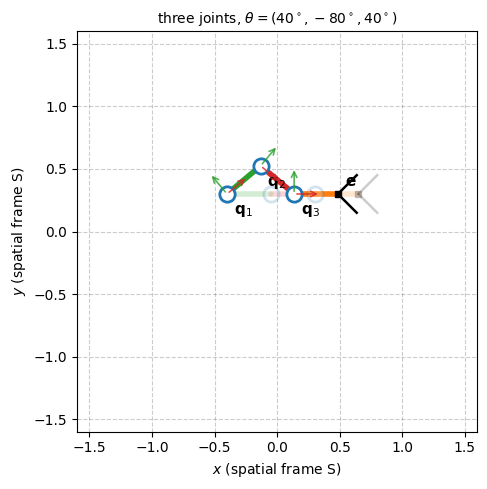

In [ ]:
if ready(joints5, e5, cu5, cl5):
    ax = new_axes(r"three joints, $\theta=(40^\circ,-80^\circ,40^\circ)$", window=params.ZOOM)
    draw_chain(ax, Q3, e3, cu3, cl3, alpha=0.2, label=False)
    draw_chain(ax, joints5, e5, cu5, cl5, thetas=theta5, frames=True)
    plt.show()
else:
    print("The plot appears as soon as the cells above are implemented.")

Record two further configurations that reach the arm end $\mathbf{e}$ of $\theta=(40^\circ,-80^\circ,40^\circ)$, as angle triples **in degrees**:
* `theta_alt_deg` — a *different* triple with the **same arm end** $\mathbf{e}$ (the claw may point elsewhere);
* `theta_alt_pose_deg` — a *different* triple with the same arm end **and the same claw orientation** ($\theta_1+\theta_2+\theta_3\equiv 0 \bmod 360^\circ$ here).

In [ ]:
#### START OF YOUR SOLUTION ####

#endpoint
X = 1 + 2 * np.cos(np.deg2rad(40))

#chosen direction
phi3 = np.deg2rad(20)

#third link vector
v3 = np.array([X - np.cos(phi3), -np.sin(phi3)])

delta = np.arctan2(v3[1], v3[0])            #direction
gamma = np.arccos(np.linalg.norm(v3)/2)     #angle

#absolute directions
phi1 = delta + gamma
phi2 = delta - gamma

theta_alt_deg = np.rad2deg([
    phi1,
    phi2 - phi1,
    phi3 - phi2
])

theta_alt_pose_deg = [-40, 80, -40]
#### END OF YOUR SOLUTION ####

In [ ]:
chk = Checker("Part 1 · Task 1.5 (other configurations)")
def _end(th):
    th = np.deg2rad(th)
    return forward_kinematics(Q3, th, e3, 3)
def _angle_sum(th): return np.mod(np.sum(th), 360.0)
chk.test("theta_alt_deg reaches the same arm end e", lambda: None if theta_alt_deg is None else (bool(np.allclose(_end(theta_alt_deg), e5, atol=1e-6)), f"arm end {np.round(_end(theta_alt_deg), 4)}"))
chk.test("...and is a different configuration", lambda: None if theta_alt_deg is None else bool(not np.allclose(np.mod(theta_alt_deg, 360), np.mod(params.THETA_SEC5_DEG, 360), atol=1e-3)))
chk.test("theta_alt_pose_deg reaches the same arm end e", lambda: None if theta_alt_pose_deg is None else (bool(np.allclose(_end(theta_alt_pose_deg), e5, atol=1e-6)), f"arm end {np.round(_end(theta_alt_pose_deg), 4)}"))
chk.test("...with the same claw orientation (sum of the angles equal mod 360°)", lambda: None if theta_alt_pose_deg is None else bool(np.isclose(np.mod(_angle_sum(theta_alt_pose_deg) - _angle_sum(params.THETA_SEC5_DEG) + 180, 360) - 180, 0, atol=1e-6)))
chk.test("...and differs from the original triple", lambda: None if theta_alt_pose_deg is None else bool(not np.allclose(np.mod(theta_alt_pose_deg, 360), np.mod(params.THETA_SEC5_DEG, 360), atol=1e-3)))

**Answer**

1. Which angles did you choose for `theta_alt_deg` and `theta_alt_pose_deg`, and how did you find them? <br />
  *For `theta_alt_pose_deg` we know the sum of the angles must be zero to preserve claw orintation. The easiest way to do that is to reflect the absolute direction of the first two links across the horizontal axis and leave the third the same -> we get the new absolute directions -40º, 40º, 0º which convert to the relative joint angles -40º, 80º, -40º.* <br />
  *For `theta_alt_deg` we can simply choose another direction for the third link, in this case 20º, and the previous two links must compensate for the change. This an be calculated by solving the vector sum equation for the endpoint as implemented in the code above*
2. How many configurations reach the same arm end $\mathbf{e}$? (Count degrees of freedom and constraints.) <br />
  *For a planar arm with three joints, there are 3 degrees of freedom - the three joint angles. The endpoint is specified by two coordinates x and y so we have two contraints. 1 degree of freedom remains. There are infinitely many configurations that reach the same endppoint*
3. How many if the claw orientation must also be the same? Why? <br />
  *If the claw must have the same orientation, we add another constraint so we are left with 0 degrees of freedom. There can be multiple solutions but in general there is a finite number of configurations. There is no longer a continuous range of possible configurations*

---
### Summary of the checks

In [ ]:
progress()

checks,passed,failed,not implemented
Part 1 · Task 1.1,8,0,0
Part 1 · Task 1.2,5,0,0
Part 1 · Task 1.3,10,0,0
Part 1 · Task 1.3 (order of the chain),4,0,0
Part 1 · Task 1.4,1,0,0
Part 1 · Task 1.4 (experiments),2,0,0
Part 1 · Task 1.5,6,0,0
Part 1 · Task 1.5 (other configurations),5,0,0


{'Part 1 · Task 1.1': {'R(90°) = [[0,-1],[1,0]]': 'pass',
  'R(30°)': 'pass',
  'the joint itself does not move: rotate_about(q, q, θ) = q': 'pass',
  'rotate_about(e, q, 50°)': 'pass',
  "e'  (your variable e_new)": 'pass',
  'claw tip e + c⁺ after the rotation (your variable cu_new)': 'pass',
  'claw tip e + c⁻ after the rotation (your variable cl_new)': 'pass',
  "the claw turns rigidly with the arm: the tip e + c⁺ moves to e' + R(θ) c⁺": 'pass'},
 'Part 1 · Task 1.2': {'final_pos has shape (50, 2)': 'pass',
  'every point is at distance |a| from the joint': 'pass',
  "the 50 angles are equally spaced and do not repeat 2π (the points' centroid is q)": 'pass',
  'the first row is e(α₀) = q + a: the angles start at 0': 'pass',
  'the second row is e(2π/50): the angles increase (counter-clockwise)': 'pass'},
 'Part 1 · Task 1.3': {'T(q, 30°) for q = (1, 2)': 'pass',
  'T leaves its own centre fixed': 'pass',
  '(a) q_2': 'pass',
  '(a) e': 'pass',
  '(a) claw tip e + c⁺': 'pass',
  '(a